<a href="https://colab.research.google.com/github/quinsan7/inteligencia_artificial/blob/main/Iris_Species_com_Arvore_de_Decis%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/menegidio/iris-species/Iris.csv
/kaggle/input/datasets/menegidio/iris-species/database.sqlite


# Iris Species com Arvore de Decisão - Com GridSearchCV

## Importar bibliotecas - Com GridSearchCV

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

## Carregar os dados - Com GridSearchCV

In [ ]:
df = pd.read_csv('/kaggle/input/datasets/menegidio/iris-species/Iris.csv')
df = df.drop(columns=['Id'])

print(df.shape)
print(df['Species'].value_counts())
df.head()

(150, 5)
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Separar X/y e treino/teste - Com GridSearchCV

In [ ]:
X = df.drop(columns=['Species'])
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)

Treino: (120, 4)
Teste: (30, 4)


## GridSearchCV

In [ ]:
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

print('Melhores parâmetros:', grid_dt.best_params_)
print('Melhor acurácia (validação cruzada):', round(grid_dt.best_score_, 4))

Melhores parâmetros: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}
Melhor acurácia (validação cruzada): 0.9417


## Acurácia e matriz de confusão - Com GridSearchCV

Acurácia treino: 0.9917
Acurácia teste : 0.9333

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



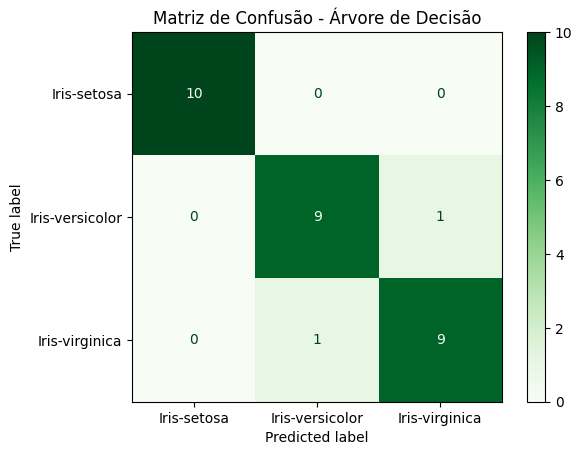

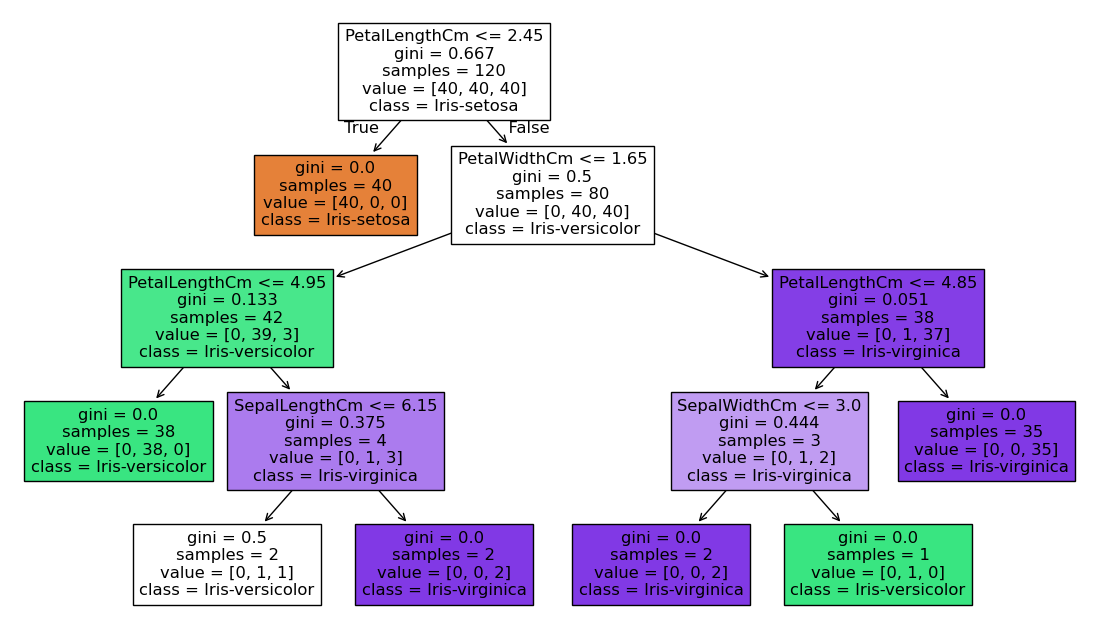

In [ ]:
best_dt = grid_dt.best_estimator_

y_pred_train_dt = best_dt.predict(X_train)
y_pred_dt = best_dt.predict(X_test)

print('Acurácia treino:', round(accuracy_score(y_train, y_pred_train_dt), 4))
print('Acurácia teste :', round(accuracy_score(y_test, y_pred_dt), 4))
print()
print(classification_report(y_test, y_pred_dt))

cm_dt = confusion_matrix(y_test, y_pred_dt, labels=best_dt.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=best_dt.classes_)
disp.plot(cmap='Greens')
plt.title('Matriz de Confusão - Árvore de Decisão')
plt.show()

plt.figure(figsize=(14, 8))
plot_tree(best_dt, feature_names=X.columns, class_names=best_dt.classes_, filled=True)
plt.show()

## Acurácia e matriz de confusão - Com GridSearchCV

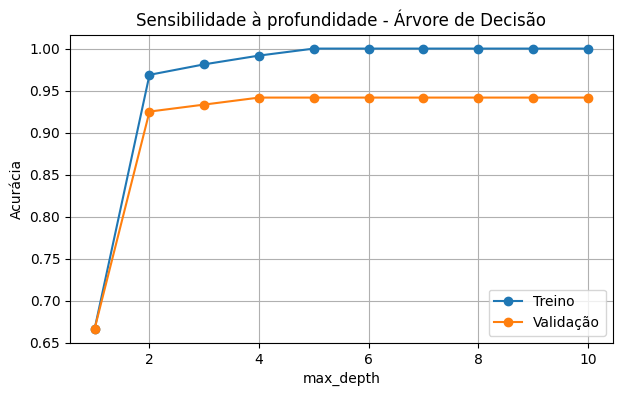

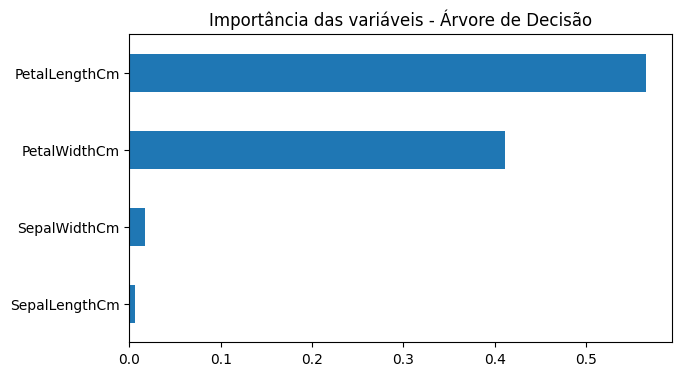

In [ ]:
param_range = range(1, 11)

train_scores, val_scores = validation_curve(
    best_dt,
    X_train,
    y_train,
    param_name='max_depth',
    param_range=param_range,
    cv=5,
    scoring='accuracy'
)

plt.figure(figsize=(7, 4))
plt.plot(param_range, train_scores.mean(axis=1), marker='o', label='Treino')
plt.plot(param_range, val_scores.mean(axis=1), marker='o', label='Validação')
plt.xlabel('max_depth')
plt.ylabel('Acurácia')
plt.title('Sensibilidade à profundidade - Árvore de Decisão')
plt.legend()
plt.grid(True)
plt.show()

# Importância das variáveis
imp_dt = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values()
imp_dt.plot(kind='barh', figsize=(7, 4), title='Importância das variáveis - Árvore de Decisão')
plt.show()

# Iris Species com Arvore de Decisão - Sem GridSearchCV

## Importar bibliotecas - Sem GridSearchCV

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
df = pd.read_csv('/kaggle/input/datasets/menegidio/iris-species/Iris.csv')
df = df.drop(columns=['Id'])

print(df.shape)
print(df['Species'].value_counts())
df.head()

(150, 5)
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
X = df.drop(columns=['Species'])
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)

Treino: (120, 4)
Teste: (30, 4)


In [ ]:
best_dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

cv_scores = cross_val_score(best_dt, X_train, y_train, cv=5, scoring='accuracy')
print('Acurácia por fold:', np.round(cv_scores, 4))
print('Acurácia média (validação cruzada):', round(cv_scores.mean(), 4))

best_dt.fit(X_train, y_train)

Acurácia por fold: [0.9167 0.9583 0.9583 0.9167 0.9167]
Acurácia média (validação cruzada): 0.9333


DecisionTreeClassifier(max_depth=3, random_state=42)

Acurácia treino: 0.9833
Acurácia teste : 0.9667

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



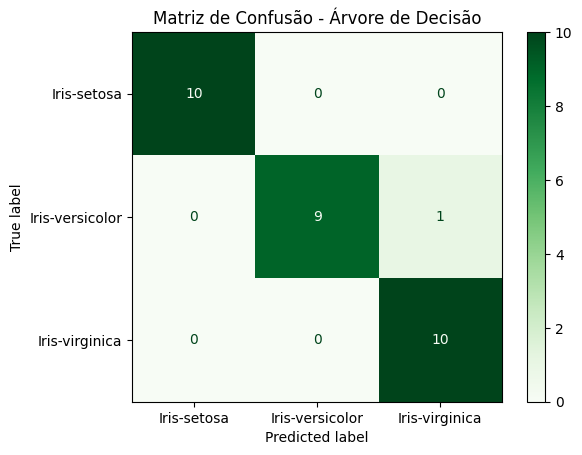

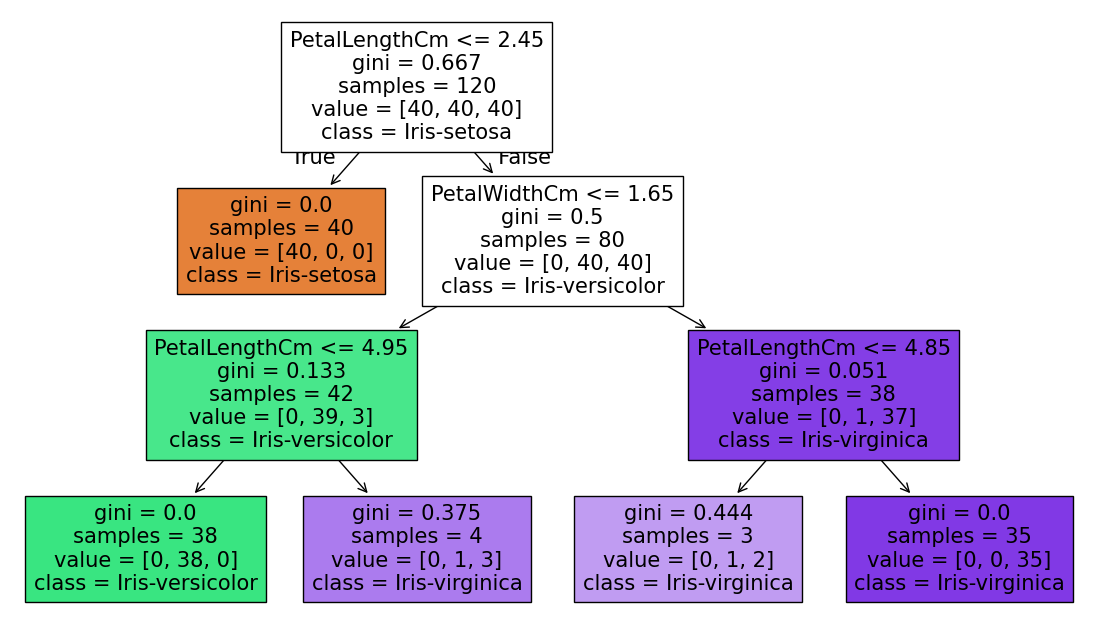

In [ ]:
y_pred_train_dt = best_dt.predict(X_train)
y_pred_dt = best_dt.predict(X_test)

print('Acurácia treino:', round(accuracy_score(y_train, y_pred_train_dt), 4))
print('Acurácia teste :', round(accuracy_score(y_test, y_pred_dt), 4))
print()
print(classification_report(y_test, y_pred_dt))

cm_dt = confusion_matrix(y_test, y_pred_dt, labels=best_dt.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=best_dt.classes_)
disp.plot(cmap='Greens')
plt.title('Matriz de Confusão - Árvore de Decisão')
plt.show()

plt.figure(figsize=(14, 8))
plot_tree(best_dt, feature_names=X.columns, class_names=best_dt.classes_, filled=True)
plt.show()

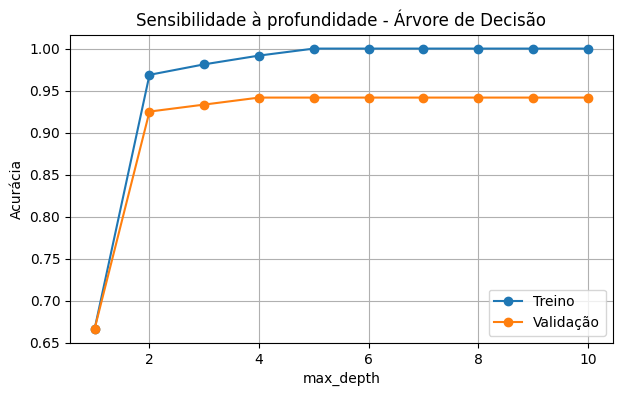

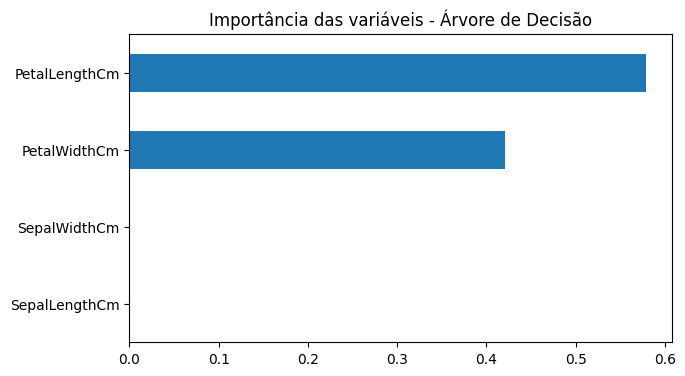

In [ ]:
param_range = range(1, 11)

train_scores, val_scores = validation_curve(
    best_dt,
    X_train,
    y_train,
    param_name='max_depth',
    param_range=param_range,
    cv=5,
    scoring='accuracy'
)

plt.figure(figsize=(7, 4))
plt.plot(param_range, train_scores.mean(axis=1), marker='o', label='Treino')
plt.plot(param_range, val_scores.mean(axis=1), marker='o', label='Validação')
plt.xlabel('max_depth')
plt.ylabel('Acurácia')
plt.title('Sensibilidade à profundidade - Árvore de Decisão')
plt.legend()
plt.grid(True)
plt.show()

# Importância das variáveis
imp_dt = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values()
imp_dt.plot(kind='barh', figsize=(7, 4), title='Importância das variáveis - Árvore de Decisão')
plt.show()

# Árvore de Decisão
Sem GridSearchCV (profundidade máxima fixada em 3), a acurácia na validação cruzada foi de 93,33% e no teste, de 96,67%. Com o GridSearchCV, o melhor modelo usou critério gini e profundidade 4, com validação cruzada de 94,17%, mas o teste caiu para 93,33%, com recall de 0,90 para Versicolor e Virginica. Ou seja, o ajuste melhorou a validação cruzada em menos de um ponto percentual e piorou o teste em uma amostra, sem ganho real. Vale observar que a versão "sem GridSearchCV" já usava uma profundidade escolhida manualmente. Foi o modelo com menor acurácia na validação cruzada nas duas configurações, o que é esperado de uma árvore única, mais instável que os métodos de conjunto.